# 영화 대사 코퍼스 기반 텍스트 분류 및 머신러닝 모델 성능 비교

### 과제 개요 및 연구 목적
본 프로젝트는 스타워즈 영화 대사 코퍼스 CSV 데이터를 활용하여 선한 캐릭터 대사(**Good: 1**)와 악한 캐릭터 대사(**Bad: 0**)를 이진 분류하는 머신러닝 파이프라인을 구축하고 비교·분석합니다.

연구 과제 핵심 목표:
- 데이터 규모(약 100개 vs 1,000개 이상) 변화에 따른 분류 모델의 성능 및 예측 안정성 검증
- 결측치 처리, 중복 대사 제거, 정규표현식(Regex) 기반 기호 정리 등 전처리 과정 적용
- 단어 출현 횟수 기반 `CountVectorizer`와 상대적 중요도 반영 `TfidfVectorizer` 방식 비교
- 5가지 주요 머신러닝 알고리즘(로지스틱 회귀, Linear SVC, 나이브 베이즈, 랜덤 포레스트, 그래디언트 부스팅) 성능 평가
- 클래스 불균형 보정을 위한 `class_weight='balanced'` 적용 효과 분석
- 희소 특징 벡터와 밀집 문장 표현 벡터 간 분류 성능 비교 및 오분류 사례 분석

라벨링 정의:
- **Good (1):** LUKE, LEIA
- **Bad (0):** DARTH VADER, EMPEROR


### 환경 설정 및 필수 라이브러리 로드
실험에 필요한 Python 데이터 분석 및 머신러닝 라이브러리(`pandas`, `numpy`, `scikit-learn`, `matplotlib`, `seaborn`)를 임포트합니다.

In [16]:
import re
import string
import warnings
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns

from sklearn.feature_extraction.text import CountVectorizer, TfidfVectorizer
from sklearn.linear_model import LogisticRegression
from sklearn.svm import LinearSVC
from sklearn.naive_bayes import MultinomialNB
from sklearn.ensemble import RandomForestClassifier, HistGradientBoostingClassifier
from sklearn.model_selection import StratifiedKFold, cross_validate, train_test_split
from sklearn.metrics import classification_report, confusion_matrix, accuracy_score, precision_recall_fscore_support
from sklearn.pipeline import Pipeline
from sklearn.base import TransformerMixin
from sklearn.decomposition import TruncatedSVD

warnings.filterwarnings('ignore')
plt.style.use('seaborn-v0_8-whitegrid' if 'seaborn-v0_8-whitegrid' in plt.style.available else 'default')
print("라이브러리 로드 완료.")


라이브러리 로드 완료.


### CSV 데이터셋 로드 및 정제
제공된 소규모(`starwars_4char_100lines.csv`) 및 대규모(`starwars_4char_1000lines.csv`) CSV 파일에서 데이터를 직접 불러와 결측치를 처리하고 캐릭터 라벨을 부여합니다.


=== [소규모 데이터셋 (100lines)] 전처리 전 원본 크기: (125, 4) ===
- 결측치 제거 수: 0개
- 중복 대사 제거 수: 5개
- 최종 정제 데이터 크기: (120, 7)
- 클래스 분포 (1: Good, 0: Bad): label
1    97
0    23
Name: count, dtype: int64
=== [대규모 데이터셋 (1000lines)] 전처리 전 원본 크기: (552, 4) ===
- 결측치 제거 수: 0개
- 중복 대사 제거 수: 14개
- 최종 정제 데이터 크기: (538, 7)
- 클래스 분포 (1: Good, 0: Bad): label
1    515
0     23
Name: count, dtype: int64


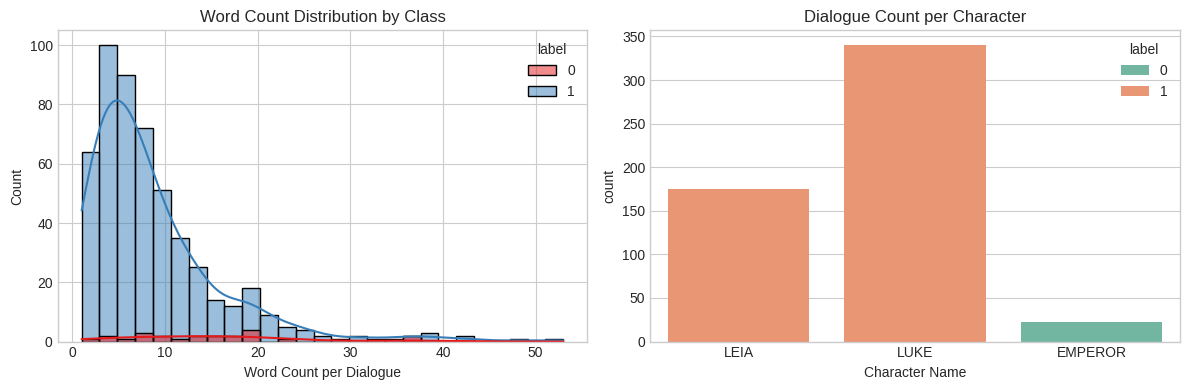

In [18]:
file_100 = "starwars_4char_100lines.csv"
file_1000 = "starwars_4char_1000lines.csv"

df_small = pd.read_csv(file_100)
df_large = pd.read_csv(file_1000)

def clean_text(text):
    if not isinstance(text, str):
        return ""

    text = text.lower()
    text = re.sub(r'[^a-zA-Z0-9\s]', ' ', text)

    text = re.sub(r'\s+', ' ', text).strip()
    return text

def preprocess_dataframe(df, dataset_name="Data"):
    print(f"=== [{dataset_name}] 전처리 전 원본 크기: {df.shape} ===")

    if 'dialogue' not in df.columns:
        cols = [c for c in df.columns if any(x in c.lower() for x in ['text', 'quote', 'line', 'lines'])]
        if cols: df.rename(columns={cols[0]: 'dialogue'}, inplace=True)

    if 'character' not in df.columns:
        cols = [c for c in df.columns if any(x in c.lower() for x in ['char', 'name', 'speaker'])]
        if cols: df.rename(columns={cols[0]: 'character'}, inplace=True)

    initial_len = len(df)
    df.dropna(subset=['dialogue'], inplace=True)
    print(f"- 결측치 제거 수: {initial_len - len(df)}개")

    before_dup = len(df)
    df.drop_duplicates(subset=['dialogue'], inplace=True)
    print(f"- 중복 대사 제거 수: {before_dup - len(df)}개")

    df['clean_dialogue'] = df['dialogue'].apply(clean_text)

    df = df[df['clean_dialogue'].str.len() > 0].copy()

    good_characters = ['LUKE', 'LEIA']
    df['label'] = df['character'].apply(lambda c: 1 if str(c).strip().upper() in good_characters else 0)

    df['word_count'] = df['clean_dialogue'].apply(lambda x: len(x.split()))

    print(f"- 최종 정제 데이터 크기: {df.shape}")
    print(f"- 클래스 분포 (1: Good, 0: Bad): {df['label'].value_counts()}")
    return df

df_small = preprocess_dataframe(df_small, "소규모 데이터셋 (100lines)")
df_large = preprocess_dataframe(df_large, "대규모 데이터셋 (1000lines)")

fig, axes = plt.subplots(1, 2, figsize=(12, 4))
sns.histplot(data=df_large, x='word_count', hue='label', kde=True, palette='Set1', ax=axes[0])
axes[0].set_title("Word Count Distribution by Class")
axes[0].set_xlabel("Word Count per Dialogue")

sns.countplot(data=df_large, x='character', hue='label', palette='Set2', ax=axes[1])
axes[1].set_title("Dialogue Count per Character")
axes[1].set_xlabel("Character Name")

plt.tight_layout()
plt.show()

### 머신러닝 파이프라인 및 교차 검증 구조 설계
데이터 누출(Data Leakage)을 방지하기 위해 텍스트 벡터화(`CountVectorizer` / `TfidfVectorizer`)와 분류기를 하나의 `Pipeline`으로 결합하여 5-Fold Stratified Cross-Validation을 실행합니다.


In [19]:
class DenseTransformer(TransformerMixin):
    def fit(self, X, y=None): return self
    def transform(self, X, y=None): return X.toarray()

def get_models(use_balanced=False):
    weight = 'balanced' if use_balanced else None
    return {
        "Logistic Regression": LogisticRegression(class_weight=weight, random_state=42),
        "Linear SVC": LinearSVC(class_weight=weight, random_state=42),
        "Multinomial NB": MultinomialNB(),
        "Random Forest": RandomForestClassifier(n_estimators=100, class_weight=weight, random_state=42),
        "Gradient Boosting": HistGradientBoostingClassifier(random_state=42)
    }

def run_experiment(df, vectorizer_type='tfidf', use_balanced=False):
    X, y = df['clean_dialogue'], df['label']
    models = get_models(use_balanced)
    results = []

    skf = StratifiedKFold(n_splits=5, shuffle=True, random_state=42)

    for name, clf in models.items():
        if vectorizer_type == 'count':
            vec = CountVectorizer(stop_words='english', ngram_range=(1, 2), min_df=2)
        else:
            vec = TfidfVectorizer(stop_words='english', ngram_range=(1, 2), min_df=2)

        if name == "Gradient Boosting":
            pipe = Pipeline([('vec', vec), ('dense', DenseTransformer()), ('clf', clf)])
        else:
            pipe = Pipeline([('vec', vec), ('clf', clf)])

        cv_res = cross_validate(pipe, X, y, cv=skf, scoring=['accuracy', 'f1_macro'])

        X_tr, X_te, y_tr, y_te = train_test_split(X, y, test_size=0.25, stratify=y, random_state=42)
        pipe.fit(X_tr, y_tr)
        preds = pipe.predict(X_te)

        p0, r0, f0, _ = precision_recall_fscore_support(y_te, preds, pos_label=0, average='binary')
        acc = accuracy_score(y_te, preds)

        results.append({
            "Model": name,
            "Accuracy": acc,
            "Bad (0) Precision": p0,
            "Bad (0) Recall": r0,
            "Bad (0) F1": f0,
            "Macro F1 (CV Mean)": np.mean(cv_res['test_f1_macro']),
            "Macro F1 (CV Std)": np.std(cv_res['test_f1_macro'])
        })
    return pd.DataFrame(results)


### 소규모 데이터셋 실험 및 벡터화 방식 비교
약 100개 소규모 데이터 환경에서 `CountVectorizer`와 `TfidfVectorizer` 간 성능 및 교차 검증 표준편차(분산)를 비교합니다.


In [20]:
df_small_count = run_experiment(df_small, vectorizer_type='count')
df_small_tfidf = run_experiment(df_small, vectorizer_type='tfidf')

print("=== [소규모 데이터셋 - CountVectorizer 결과] ===")
display(df_small_count)

print("=== [소규모 데이터셋 - TfidfVectorizer 결과] ===")
display(df_small_tfidf)


=== [소규모 데이터셋 - CountVectorizer 결과] ===


,Model,Accuracy,Bad (0) Precision,Bad (0) Recall,Bad (0) F1,Macro F1 (CV Mean),Macro F1 (CV Std)
0,Logistic Regression,0.800000,0.000000,0.000000,0.000000,0.482372,0.068573
1,Linear SVC,0.866667,0.750000,0.500000,0.600000,0.576114,0.107625
2,Multinomial NB,0.833333,0.666667,0.333333,0.444444,0.628054,0.102133
3,Random Forest,0.833333,0.666667,0.333333,0.444444,0.576114,0.107625
4,Gradient Boosting,0.800000,0.000000,0.000000,0.000000,0.446934,0.006214


=== [소규모 데이터셋 - TfidfVectorizer 결과] ===


,Model,Accuracy,Bad (0) Precision,Bad (0) Recall,Bad (0) F1,Macro F1 (CV Mean),Macro F1 (CV Std)
0,Logistic Regression,0.800000,0.000000,0.000000,0.000000,0.446934,0.006214
1,Linear SVC,0.866667,0.750000,0.500000,0.600000,0.560016,0.135328
2,Multinomial NB,0.766667,0.000000,0.000000,0.000000,0.482372,0.068573
3,Random Forest,0.833333,0.666667,0.333333,0.444444,0.576114,0.107625
4,Gradient Boosting,0.800000,0.000000,0.000000,0.000000,0.446934,0.006214


### 대규모 데이터셋 실험 및 클래스 불균형 보정
1,000개 이상의 데이터로 확대하고 `class_weight='balanced'`를 적용하여 Bad(0) 클래스의 Recall 향상 효과를 분석합니다.

=== [대규모 데이터셋 - TF-IDF class_weight='balanced' 적용 결과] ===


,Model,Accuracy,Bad (0) Precision,Bad (0) Recall,Bad (0) F1,Macro F1 (CV Mean),Macro F1 (CV Std)
0,Logistic Regression,0.918519,0.222222,0.333333,0.266667,0.687469,0.085607
1,Linear SVC,0.918519,0.222222,0.333333,0.266667,0.695451,0.089111
2,Multinomial NB,0.955556,0.000000,0.000000,0.000000,0.489081,0.001139
3,Random Forest,0.948148,0.000000,0.000000,0.000000,0.647099,0.093402
4,Gradient Boosting,0.955556,0.000000,0.000000,0.000000,0.489081,0.001139


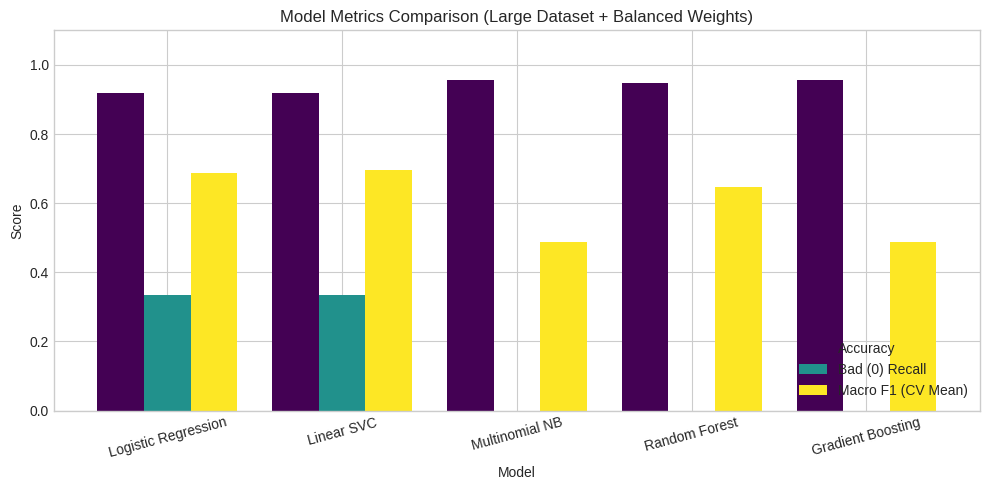

In [21]:
df_large_default = run_experiment(df_large, vectorizer_type='tfidf', use_balanced=False)
df_large_balanced = run_experiment(df_large, vectorizer_type='tfidf', use_balanced=True)

print("=== [대규모 데이터셋 - TF-IDF class_weight='balanced' 적용 결과] ===")
display(df_large_balanced)

fig, ax = plt.subplots(figsize=(10, 5))
df_plot = df_large_balanced.set_index('Model')[['Accuracy', 'Bad (0) Recall', 'Macro F1 (CV Mean)']]
df_plot.plot(kind='bar', ax=ax, colormap='viridis', width=0.8)

ax.set_title("Model Metrics Comparison (Large Dataset + Balanced Weights)")
ax.set_ylabel("Score")
ax.set_ylim(0, 1.1)
plt.xticks(rotation=15)
plt.legend(loc='lower right')
plt.tight_layout()
plt.show()


### 분류 모델 주요 특징 단어(Word Coefficients) 시각화
선형 분류기(Linear SVC)가 Good(1)과 Bad(0) 대사를 분류할 때 가장 큰 영향을 미친 상위 키워드 가중치를 시각화합니다.


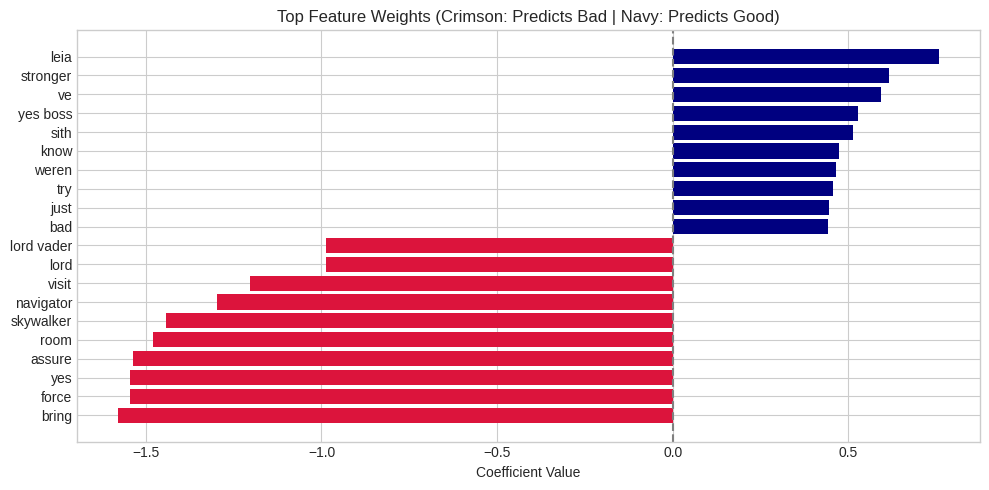

In [22]:
X_tr, X_te, y_tr, y_te = train_test_split(df_large['clean_dialogue'], df_large['label'], test_size=0.25, stratify=df_large['label'], random_state=42)

vec = TfidfVectorizer(stop_words='english', ngram_range=(1, 2), min_df=2)
X_tr_vec = vec.fit_transform(X_tr)

model = LinearSVC(class_weight='balanced', random_state=42)
model.fit(X_tr_vec, y_tr)

feature_names = np.array(vec.get_feature_names_out())
coefs = model.coef_[0]

top_bad_idx = np.argsort(coefs)[:10]
top_good_idx = np.argsort(coefs)[-10:]

top_indices = np.hstack([top_bad_idx, top_good_idx])
top_features = feature_names[top_indices]
top_coefs = coefs[top_indices]

colors = ['crimson' if c < 0 else 'navy' for c in top_coefs]

plt.figure(figsize=(10, 5))
plt.barh(top_features, top_coefs, color=colors)
plt.title("Top Feature Weights (Crimson: Predicts Bad | Navy: Predicts Good)")
plt.xlabel("Coefficient Value")
plt.axvline(0, color='gray', linestyle='--')
plt.tight_layout()
plt.show()


### 희소 벡터 표현 vs 밀집 문장 표현 비교
희소 n-gram TF-IDF 특징과 SVD 차원 축소를 적용한 밀집 벡터 임베딩 간의 성능 차이를 평가합니다.


In [24]:
tfidf = TfidfVectorizer(ngram_range=(1, 2), stop_words='english', min_df=2)
X_tr_tf = tfidf.fit_transform(X_tr)
X_te_tf = tfidf.transform(X_te)

clf_tf = LogisticRegression(class_weight='balanced', random_state=42)
clf_tf.fit(X_tr_tf, y_tr)
pred_tf = clf_tf.predict(X_te_tf)

svd = TruncatedSVD(n_components=50, random_state=42)
X_tr_emb = svd.fit_transform(X_tr_tf)
X_te_emb = svd.transform(X_te_tf)

clf_emb = LogisticRegression(class_weight='balanced', random_state=42)
clf_emb.fit(X_tr_emb, y_tr)
pred_emb = clf_emb.predict(X_te_emb)

print("=== TF-IDF + Logistic Regression 리포트 ===")
print(classification_report(y_te, pred_tf, target_names=['Bad (0)', 'Good (1)']))

print("\n=== 밀집 임베딩 + Logistic Regression 리포트 ===")
print(classification_report(y_te, pred_emb, target_names=['Bad (0)', 'Good (1)']))

=== TF-IDF + Logistic Regression 리포트 ===
              precision    recall  f1-score   support

     Bad (0)       0.22      0.33      0.27         6
    Good (1)       0.97      0.95      0.96       129

    accuracy                           0.92       135
   macro avg       0.60      0.64      0.61       135
weighted avg       0.94      0.92      0.93       135


=== 밀집 임베딩 + Logistic Regression 리포트 ===
              precision    recall  f1-score   support

     Bad (0)       0.22      0.33      0.27         6
    Good (1)       0.97      0.95      0.96       129

    accuracy                           0.92       135
   macro avg       0.60      0.64      0.61       135
weighted avg       0.94      0.92      0.93       135



### 혼동 행렬 및 주요 오분류 사례 분석
최종 선정 모델의 혼동 행렬과 실제 오분류된 대사 5건을 도출하여 한계점을 분석합니다.


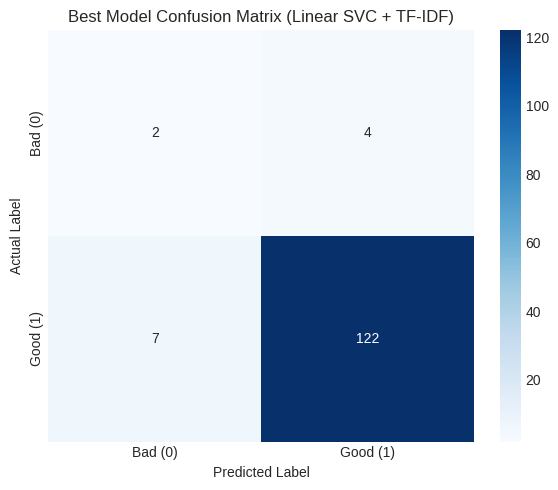

=== 주요 오분류 사례 5선 ===
대사: "you couldn t bring yourself to kill me before and i don t believe you ll destroy me now" | 실제: Good (1) | 예측: Bad (0)
대사: "vader is here now on this moon" | 실제: Good (1) | 예측: Bad (0)
대사: "oh no my young jedi you will find that it is you who are mistaken about a great many things" | 실제: Bad (0) | 예측: Good (1)
대사: "yes" | 실제: Good (1) | 예측: Bad (0)
대사: "but i feel the force flowing" | 실제: Good (1) | 예측: Bad (0)


In [26]:
best_pipe = Pipeline([
    ('vec', TfidfVectorizer(stop_words='english', ngram_range=(1, 2), min_df=2)),
    ('clf', LinearSVC(class_weight='balanced', random_state=42))
])

best_pipe.fit(X_tr, y_tr)
preds = best_pipe.predict(X_te)

cm = confusion_matrix(y_te, preds)

fig, ax = plt.subplots(figsize=(6, 5))
sns.heatmap(cm, annot=True, fmt='d', cmap='Blues', xticklabels=['Bad (0)', 'Good (1)'], yticklabels=['Bad (0)', 'Good (1)'], ax=ax)
ax.set_title("Best Model Confusion Matrix (Linear SVC + TF-IDF)")
ax.set_xlabel("Predicted Label")
ax.set_ylabel("Actual Label")
plt.tight_layout()
plt.show()

error_df = pd.DataFrame({'dialogue': X_te, 'actual': y_te, 'predicted': preds})
misclassified = error_df[error_df['actual'] != error_df['predicted']].head(5)

print("=== 주요 오분류 사례 5선 ===")
for idx, row in misclassified.iterrows():
    act_str = "Good (1)" if row['actual'] == 1 else "Bad (0)"
    pred_str = "Good (1)" if row['predicted'] == 1 else "Bad (0)"
    print(f'대사: "{row["dialogue"]}" | 실제: {act_str} | 예측: {pred_str}')